In [1]:
import torch
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

Device: mps


In [2]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipeline = StableDiffusionPipeline.from_pretrained(model_id)
pipeline = pipeline.to(device)
pipeline.enable_attention_slicing()

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

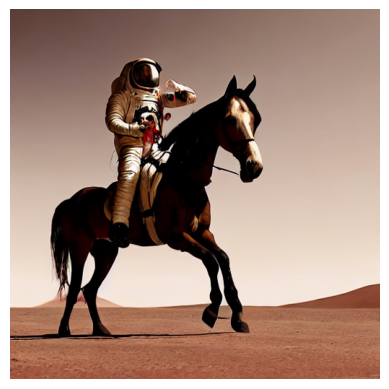

In [3]:
prompt = "A photo of an astronaut riding a horse on mars"
guidance_scale = 7.5
steps = 50
num_images = 1

result = pipeline(
    prompt=prompt,
    num_images_per_prompt=num_images,
    guidance_scale=guidance_scale,
    num_inference_steps=steps
)
image = result.images[0]

plt.imshow(image)
plt.axis('off')
plt.show()
image.save("generated_image.png")

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

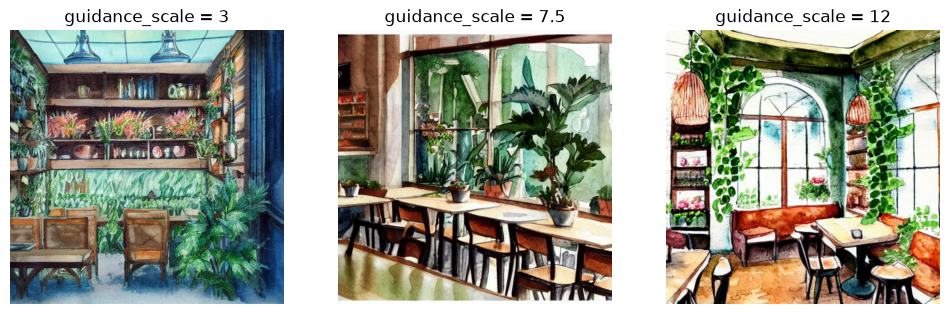

In [4]:
prompt = "A cozy cafe interior with plants, warm lighting, watercolor style"
scales = [3, 7.5, 12]

plt.figure(figsize=(12, 4))
for i, gs in enumerate(scales):
    img = pipeline(prompt=prompt, guidance_scale=gs, num_inference_steps=30).images[0]
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"guidance_scale = {gs}")
    plt.axis('off')
plt.show()

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

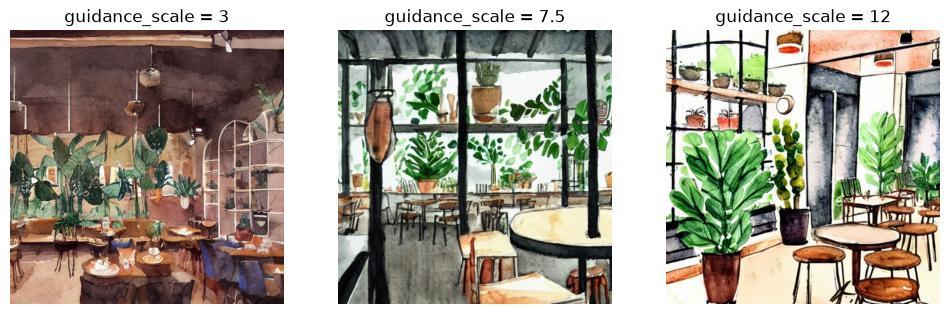

In [5]:
prompt = "A cozy cafe interior with plants, warm lighting, watercolor style"
steps_list = [10, 25, 50]

plt.figure(figsize=(12, 4))
for i, gs in enumerate(scales):
    img = pipeline(prompt=prompt, guidance_scale=gs, num_inference_steps=30).images[0]
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"guidance_scale = {gs}")
    plt.axis('off')
plt.show()